# The link-layer playground

What might ride on the modem: the experiments of `tools/toystack.py` (docs/PLAN.md, S8).
Its frame format and protocols are drafts for experiments, not decisions; this notebook is
about what the 110 waveform's behaviour means for any protocol built on it.

It is generated from `docs/playground.py` (`python tools/build_notebook.py playground`), and
the test suite runs that script. Every session below runs through the Appendix E channel
(2 paths, 2 ms, 1 Hz unless said otherwise) and the complete receiver; one run is one
sample of the fading, not a measurement.

In [1]:
import sys
import zlib

import matplotlib.pyplot as plt
import numpy as np
from nbtools import DOCS, QUICK

from m110c.channel.schedule import Schedule
from m110c.spec import mode
from m110c.spec import tables as T
from m110c.tx import transmit_bytes

sys.path.insert(0, str(DOCS.parent / "tools"))
import toystack as toy  # noqa: E402

plt.rcParams["figure.figsize"] = (8, 3.5)
RATES = (2400, 1200, 600, 300, 150, 75)
RATE_COLOUR = {r: f"C{i}" for i, r in enumerate(RATES)}  # fixed per rate, in every figure

## 1. A frame, byte by byte

The draft frame: a sync word the receiver hunts for, a header naming the type, flags,
sender, addressee, a sequence number and the payload's length, then the payload and a
CRC-32. A transmission is one 110 message carrying any number of frames back to back; a
frame damaged by the channel fails its CRC and costs only itself, because the parser
goes on hunting for the next sync word. The 26 bytes of overhead are 11% of a 200-byte
block, and most of a one-line chat message.

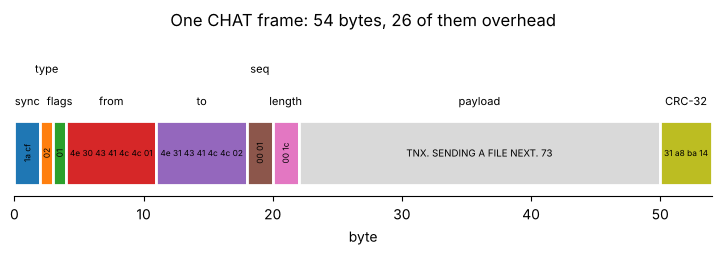

[('CHAT', 1, b'N0CALL\x01', b'N1CALL\x02', 1, b'TNX. SENDING A FILE NEXT. 73')]


In [2]:
station = toy.Station(toy.A)
text = b"TNX. SENDING A FILE NEXT. 73"
frame = station.frame("CHAT", toy.B, text, toy.OVER)
fields = [
    ("sync", 2),
    ("type", 1),
    ("flags", 1),
    ("from", 7),
    ("to", 7),
    ("seq", 2),
    ("length", 2),
    ("payload", len(text)),
    ("CRC-32", 4),
]
assert sum(n for _, n in fields) == len(frame)
fig, ax = plt.subplots(figsize=(9, 2.1))
start = 0
for i, (name, n) in enumerate(fields):
    colour = "0.85" if name == "payload" else f"C{i % 10}"
    ax.barh(0, n, left=start, height=0.6, color=colour, edgecolor="white", linewidth=2)
    lift = 0.3 if n < 3 and i % 2 else 0.0  # stagger the narrow fields' names
    ax.text(start + n / 2, 0.42 + lift, name, ha="center", va="bottom", fontsize=8)
    if name != "payload":
        ax.text(
            start + n / 2,
            0,
            frame[start : start + n].hex(" "),
            ha="center",
            va="center",
            fontsize=6,
            rotation=90 if n < 3 else 0,
        )
    else:
        ax.text(start + n / 2, 0, text.decode(), ha="center", va="center", fontsize=7)
    start += n
ax.set_xlim(0, len(frame))
ax.set_ylim(-0.4, 1.1)
ax.set_yticks([])
ax.set_xlabel("byte")
ax.set_title(f"One CHAT frame: {len(frame)} bytes, {toy.OVERHEAD} of them overhead")
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
plt.show()
print(toy.parse(b"noise" + frame + b"more noise")[0])

## 2. Every transmission has a fixed cost

A transmission is a preamble (0.6 s with zero or short interleave, 4.8 s with long), the
data, then the end-of-message marker and the flush, padded to the end of an interleaver
block. However small the message, that much is sent. So the fraction of the air time that
carries the message grows with its size, and much more slowly with long interleave: a
200-byte message at 1200L spends most of its 9.6 s on overhead. This is why a protocol
over 110 batches its frames, piggybacks its acknowledgements, and keeps long interleave
for long messages. The sawtooth is the padding: a transmission always ends on a whole
interleaver block, so a message just over a block boundary pays for nearly a whole block.

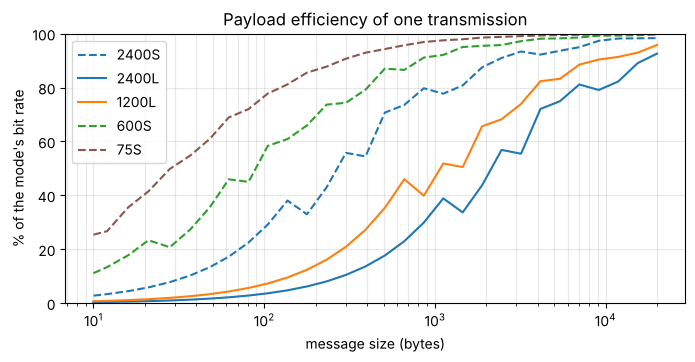

In [3]:
sizes = np.unique(np.geomspace(10, 20_000, 12 if QUICK else 30).astype(int))
for rate, interleave in (
    (2400, "short"),
    (2400, "long"),
    (1200, "long"),
    (600, "short"),
    (75, "short"),
):
    m = mode(rate, interleave)
    seconds = np.array([transmit_bytes(bytes(n), m).size / T.SYMBOL_RATE for n in sizes])
    efficiency = 8 * sizes / seconds / rate
    style = "-" if interleave == "long" else "--"
    plt.semilogx(sizes, 100 * efficiency, style, color=RATE_COLOUR[rate], label=str(m))
plt.xlabel("message size (bytes)")
plt.ylabel("% of the mode's bit rate")
plt.title("Payload efficiency of one transmission")
plt.ylim(0, 100)
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

## 3. A session on the air

Store-and-forward mail between two stations, in turns: hello and hello back, A's
proposals (message id, size, compressed size), B's accept or reject (it already has one
of the two messages, so that one is never sent), the transfer at 1200L, B's
acknowledgement, bye. Each bar is one transmission; the half-second gaps are the assumed
radio turnarounds. Short control exchanges use 1200S (0.6-s preamble); only the transfer
pays for long interleave's 4.8-s preamble. Even so, the transfer is less than half the
session, and the useful rate end to end is well under the mode's 1200 bps.

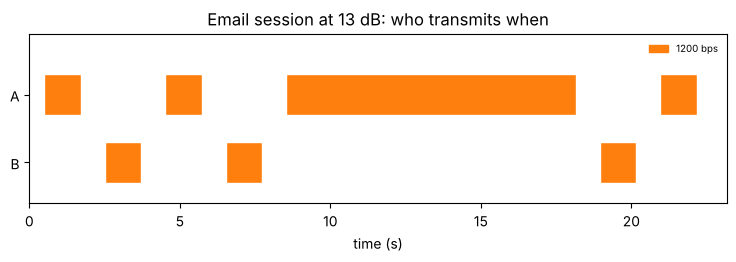

  0.5 s  A  1200S  1.2 s  1/1 frames  email: hello
  2.5 s  B  1200S  1.2 s  1/1 frames  email: hello back
  4.5 s  A  1200S  1.2 s  1/1 frames  email: proposals (id, size, packed)
  6.5 s  B  1200S  1.2 s  1/1 frames  email: accept + / reject -
  8.5 s  A  1200L  9.6 s  3/3 frames  email: transfer 3 block(s)
 18.9 s  B  1200S  1.2 s  1/1 frames  email: ack (all received)
 21.0 s  A  1200S  1.2 s  1/1 frames  email: bye (B would now propose its own)
1862 useful bytes in a 22.2-s session: 672 bps end to end; the transfer took 9.6 s


In [4]:
def lanes(ax, air, t_max=None):
    """The session's transmissions as bars, one lane per station, coloured by rate and
    hatched where frames were lost (lost/sent written beside them)."""
    for e in air.timeline:
        y = 1 if e["sender"] == "A" else 0
        lost = e["sent"] - e["received"]
        ax.barh(
            y,
            e["seconds"],
            left=e["start_s"],
            height=0.6,
            color=RATE_COLOUR[e["rate"]],
            hatch="////" if lost else None,
            edgecolor="white",
            linewidth=1,
        )
        if lost:
            ax.text(
                e["start_s"] + e["seconds"],
                y + 0.32,
                f"{lost}/{e['sent']} lost",
                fontsize=7,
                va="bottom",
            )
    ax.set_yticks([0, 1], ["B", "A"])
    ax.set_ylim(-0.6, 1.9)
    ax.set_xlim(0, t_max or max(e["start_s"] + e["seconds"] for e in air.timeline) + 1)
    used = sorted({e["rate"] for e in air.timeline}, reverse=True)
    handles = [plt.Rectangle((0, 0), 1, 1, color=RATE_COLOUR[r]) for r in used]
    ax.legend(
        handles,
        [f"{r} bps" for r in used],
        loc="upper right",
        ncol=len(used),
        fontsize=7,
        frameon=False,
    )


air, result = toy.email(quiet=True)
fig, ax = plt.subplots(figsize=(9, 2.2))
lanes(ax, air)
ax.set_xlabel("time (s)")
ax.set_title("Email session at 13 dB: who transmits when")
plt.show()
for e in air.timeline:
    print(
        f"{e['start_s']:5.1f} s  {e['sender']}  {e['mode']:5s} {e['seconds']:4.1f} s  "
        f"{e['received']}/{e['sent']} frames  {e['label']}"
    )
transfer = sum(e["seconds"] for e in air.timeline if "transfer" in e["label"])
end = max(e["start_s"] + e["seconds"] for e in air.timeline)
print(
    f"{result['useful_bytes']} useful bytes in a {end:.1f}-s session: "
    f"{8 * result['useful_bytes'] / end:.0f} bps end to end; the transfer took {transfer:.1f} s"
)

## 4. Negotiating the mode

The channel notebook showed that the best rate depends on the SNR, so a link should choose
its mode from the conditions. Here A sends a file in rounds of six coded blocks; after
each round B measures the SNR of what it received, and proposes the next round's mode in
its status reply: the fastest long-interleave mode whose Table XVI SNR the estimate clears
by 2 dB (the receiver's SNR estimate reads 3-4 dB low, so 3.5 dB is added first). After a
clean round the mode moves at most one rung; losses let it drop at once. Lost blocks are
replaced by further fountain-coded ones (section 5), and a lost status reply is polled
for.

The file is 14 kB of already-compressed data, about 70 blocks. The channel SNR follows a
schedule: 20 dB, a slide to 6 dB, a minute there, and back to 20 dB, much faster than real
conditions change, to show the protocol's behaviour in one figure.

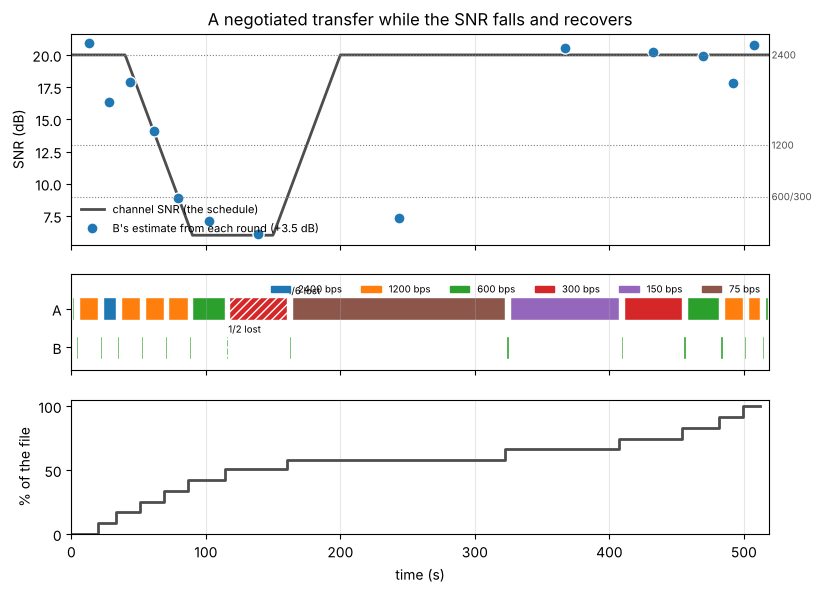

14000 bytes (71 blocks of 200 compressed) in 509 s, 220 bps end to end; modes: 1200L, 2400L, 1200L, 600L, 300L, 75L, 150L, 300L, 600L, 1200L


In [5]:
# Random bytes stand in for a file that is already compressed (zlib leaves them as they are).
text = np.random.default_rng(5).integers(0, 256, 2_000 if QUICK else 14_000, np.uint8).tobytes()
snr = Schedule(((0, 20), (40, 20), (90, 6), (150, 6), (200, 20)))
air, result = toy.negotiated(snr, text, seed=60, quiet=True, title="rise and fall")
k = -(-len(zlib.compress(text, 9)) // 200)
t_end = max(e["start_s"] + e["seconds"] for e in air.timeline) + 1

fig, ax = plt.subplots(
    3, 1, figsize=(9, 6.5), sharex=True, gridspec_kw={"height_ratios": [2.2, 1, 1.4]}
)
t = np.linspace(0, t_end, 600)
ax[0].plot(t, snr.value(t), color="0.3", lw=2, label="channel SNR (the schedule)")
data_tx = [e for e in air.timeline if e["sender"] == "A" and "transfer" in e["label"]]
heard = [e for e in data_tx if e["measured_db"] is not None]
ax[0].plot(
    [e["start_s"] + e["seconds"] / 2 for e in heard],
    [e["measured_db"] + toy.CAL_OFFSET_DB for e in heard],
    "o",
    ms=8,
    color="C0",
    markeredgecolor="white",
    label="B's estimate from each round (+3.5 dB)",
)
thresholds = {}  # 600 and 300 bps share Table XVI's 7 dB
for rate, needed in toy.MODE_LADDER[:4]:
    thresholds.setdefault(needed + toy.MARGIN_DB, []).append(str(rate))
for level, names in thresholds.items():
    ax[0].axhline(level, color="0.5", lw=0.8, ls=":")
    ax[0].text(t_end, level, " " + "/".join(names), color="0.3", fontsize=7, va="center")
ax[0].set_ylabel("SNR (dB)")
ax[0].legend(loc="lower left", fontsize=8, frameon=False)
ax[0].set_title("A negotiated transfer while the SNR falls and recovers")
lanes(ax[1], air, t_end)
received, times = 0, [0.0]
progress = [0.0]
for e in data_tx:
    received += e["received"]
    times.append(e["start_s"] + e["seconds"])
    progress.append(min(1.0, received / k))
ax[2].step(times, 100 * np.array(progress), where="post", color="0.3", lw=2)
ax[2].set_ylabel("% of the file")
ax[2].set_ylim(0, 105)
ax[2].set_xlabel("time (s)")
for a in ax:
    a.grid(True, axis="x", alpha=0.3)
plt.show()
print(
    f"{len(text)} bytes ({k} blocks of 200 compressed) in {result['seconds']:.0f} s, "
    f"{result['bps']:.0f} bps end to end; modes: {', '.join(result['modes'])}"
)

The dotted lines are the thresholds (Table XVI's SNR plus the 2-dB margin) for 2400, 1200,
600 and 300 bps. What the figure shows about this draft protocol:

* **It follows the fall.** As the SNR slides, the rounds step down through the ladder and
  keep delivering: no data round loses a block to the fade, which is the point of
  negotiating. (One short status reply was lost at 6 dB; A polled and heard it again.)
* **Every decision is one round late, and slow rounds are long.** A round is six blocks
  whatever the rate, so at 150 bps it lasts over a minute, chosen from an SNR measured
  before it began. In the full run, the 150-bps round is decided at 6 dB and then sent
  while the SNR climbs back to 20.
* **Recovery is slow.** After a clean round the mode rises one rung at a time, so climbing
  back from 150 to 1200 bps takes several more long rounds.

Both point the same way for S8: size a round in *seconds*, not in blocks, so the protocol
hears back at a steady pace at every rate, and let a clearly better measurement skip rungs
upward as losses already skip them downward. (The SNR estimates scatter by a few dB around
the schedule: each is one transmission's average over a fading channel.)

## 5. Repairing losses with a fountain code

Over a link with long turnarounds, asking for specific lost blocks costs a round trip per
repair. A *fountain code* sends instead as many coded blocks as needed, each a random XOR
of the source blocks, and the receiver rebuilds the file from *any* k of them that are
independent (Gaussian elimination over GF(2)), whichever were lost. The toy code is
systematic: the first k blocks are the source blocks themselves.

Compared with a carousel (send the source blocks over and over until each has arrived),
at 30% block loss: the carousel's last few blocks take long to arrive (each round
delivers only 70% of what is still missing), while every fountain block received is new
information until the file is complete.

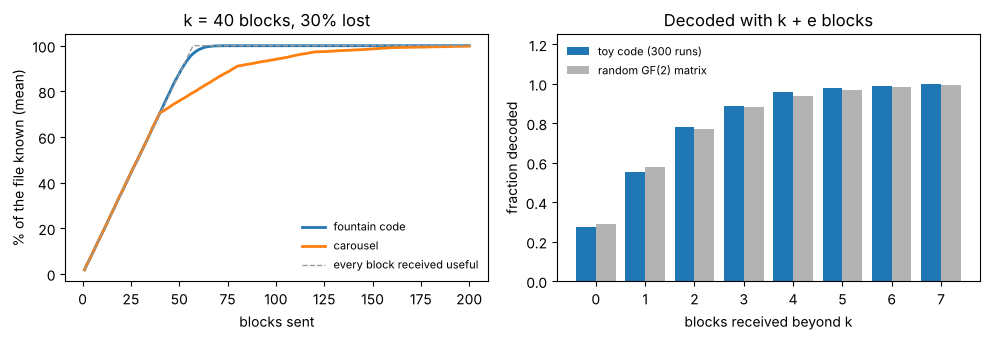

fountain: decoded from k + 1.6 blocks received on average; median blocks sent until the file is known: fountain 59, carousel 140


In [6]:
def rank_after_each(k, seeds, lost):
    """Independent blocks received (GF(2) rank) after each block sent."""
    basis, out = {}, []  # pivot bit -> row, rows as Python integers
    for seed, gone in zip(seeds, lost, strict=True):
        if not gone:
            row = int("".join("1" if b else "0" for b in toy.fountain_mask(k, seed)), 2)
            while row:
                top = row.bit_length() - 1
                if top not in basis:
                    basis[top] = row
                    break
                row ^= basis[top]
        out.append(len(basis))
    return np.array(out)


k, loss, n = 40, 0.3, 200
trials = 30 if QUICK else 300
rng = np.random.default_rng(1)
fountain, carousel, extra = [], [], []
for _ in range(trials):
    lost = rng.random(n) < loss
    r = rank_after_each(k, range(n), lost)
    fountain.append(r)
    seen = np.zeros(k, bool)
    c = []
    for i in range(n):
        seen[i % k] |= not lost[i]
        c.append(seen.sum())
    carousel.append(c)
    if r[-1] == k:
        received_at_k = int(np.sum(~lost[: np.argmax(r == k) + 1]))
        extra.append(received_at_k - k)
sent = np.arange(1, n + 1)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(sent, np.mean(fountain, 0) / k * 100, color="C0", lw=2, label="fountain code")
ax[0].plot(sent, np.mean(carousel, 0) / k * 100, color="C1", lw=2, label="carousel")
ax[0].plot(
    sent,
    np.minimum(100, (1 - loss) * sent / k * 100),
    color="0.6",
    lw=1,
    ls="--",
    label="every block received useful",
)
ax[0].set_xlabel("blocks sent")
ax[0].set_ylabel("% of the file known (mean)")
ax[0].set_title(f"k = {k} blocks, {loss:.0%} lost")
ax[0].legend(fontsize=8, frameon=False)
e = np.arange(0, 8)
measured = [np.mean(np.array(extra) <= x) for x in e]
theory = [np.prod([1 - 2.0 ** -(x + i) for i in range(1, k + 1)]) for x in e]
ax[1].bar(e - 0.2, measured, width=0.4, color="C0", label=f"toy code ({trials} runs)")
ax[1].bar(e + 0.2, theory, width=0.4, color="0.7", label="random GF(2) matrix")
ax[1].set_xlabel("blocks received beyond k")
ax[1].set_ylabel("fraction decoded")
ax[1].set_title("Decoded with k + e blocks")
ax[1].legend(fontsize=8, frameon=False, loc="upper left")
ax[1].set_ylim(0, 1.25)
plt.tight_layout()
plt.show()


def sent_until_complete(curves):
    """Median blocks sent before the whole file was known (runs that never got there
    count as more than n)."""
    done = [np.argmax(np.asarray(c) == k) + 1 if c[-1] == k else np.inf for c in curves]
    return np.median(done)


print(
    f"fountain: decoded from k + {np.mean(extra):.1f} blocks received on average; median "
    f"blocks sent until the file is known: fountain {sent_until_complete(fountain):.0f}, "
    f"carousel {sent_until_complete(carousel):.0f}"
)

A random binary matrix with k + e rows has full rank with probability
prod_{i=1..k} (1 - 2^-(e+i)): about 29% with no extra block, 58% with one, 77% with two,
and then the shortfall halves with each one more. The toy code follows it (its source
blocks help a little: unit rows are independent of each other). Practical codes
(RaptorQ, RFC 6330) do better still, decoding almost always from k or k + 1 blocks with far
less arithmetic; the toy is for seeing the idea, not for use.